# 1. Problem and real field data
Recover five conditional optical properties from180real Finse snow spectra. Darkening from algae,dust and dark particles overlaps with grain/water absorption. The known response was trained on an independent5.8million-simulation BioSNICAR grid,not field labels. This notebook actively executes the complete selectedpublishedemulatorinverse. No independent field-property ground truth exists.

| Quantity | Unit | Role |
|---|---|---|
| Field HCRF |1|180spectra,2151bands350..2500nm |
| Effective grain radius |micrometre|Unknown spherical-equivalent grain scale |
| Red algae |cells/mL|Unknown2cm-equivalent concentration |
| Liquid water |volume fraction|Unknown common two-layer wetness |
| Dark particles and dust |ppb=ng/g|Unknown optical-equivalent abundances |
| Nominal angle |degree|Known author effective calibration,not independently verified solar geometry |

The field measurements use nadir25degree view and calibratedSpectralonreference,10replicates. No chemical BC measurement establishes actualBC; that component represents particles withBC-likeoptics. Photographs and quantitative chemicaltruth from new fieldwork are unavailable; this review retains real spectra and infers optical signatures without inventing photographs or labels.

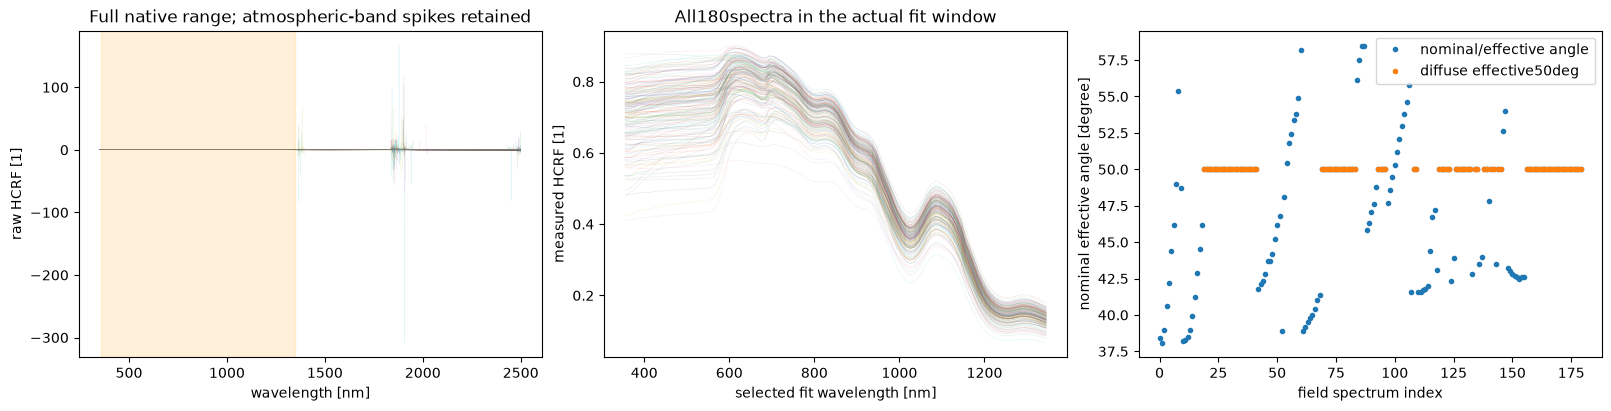

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown,display
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load
from src.physics_model import forward,spectrum
from src.solvers import reconstruct
from src.visualization import property_panels,selected_spectra,LABELS
d=load();wave=295+10*np.arange(212);target=d['spectra'][:,5::10][:,:100]
fig,axs=plt.subplots(1,3,figsize=(16,4),layout='constrained')
for row in d['spectra']:
 axs[0].plot(d['wavelengths'],row,lw=.3,alpha=.15)
 axs[1].plot(np.arange(355,1346,10),row[5::10][:100],lw=.4,alpha=.15)
axs[0].set_xlabel('wavelength [nm]');axs[0].set_ylabel('raw HCRF [1]');axs[0].set_title('Full native range; atmospheric-band spikes retained');axs[0].axvspan(355,1345,color='orange',alpha=.15)
axs[1].set_xlabel('selected fit wavelength [nm]');axs[1].set_ylabel('measured HCRF [1]');axs[1].set_title('All180spectra in the actual fit window')
axs[2].plot(d['solar_zenith'],'.',label='nominal/effective angle');axs[2].plot(np.where(d['diffuse']==1)[0],d['solar_zenith'][d['diffuse']==1],'o',ms=3,label='diffuse effective50deg');axs[2].set_xlabel('field spectrum index');axs[2].set_ylabel('nominal effective angle [degree]');axs[2].legend();plt.show()


# 2. Response physics and inverse mathematics
Let v=(theta,r,a,l,b,d) be nominal angle,grain radius,algae,LWC,dark-equivalent and dust in the units above. Visible scales s and offsets o transform x=v*s+o. All calibrated coefficient arrays are independent forward-response weights.

$$h_0=x,\quad z_{k+1}=h_kW_k+b_k,\quad h_{k+1}=\operatorname{ELU}(z_{k+1})\ (k<11),\quad h_{12}=z_{12},$$
$$\operatorname{ELU}(z)=z\quad(z>0),\qquad \operatorname{ELU}(z)=e^z-1\quad(z\le0).$$

The final212values predict albedo at295..2405nm. Eleven hiddenELUlayersandone linearoutputlayer are the actual archived calibration. The physicalsimulator behind it uses0.02mLAP-bearing snow over100mcleansnow,density600kg/m3,sphericalequivalentgrains and commonradius/wetness.

For each restart minimize L=sum(residual²)/2on100bands355..1345nm. Explicit chainrule throughELU and matrixtransposes gives gradient g;SZAgradient is0. AdaGrad uses

$$A^{new}=A+g^2,\qquad x^{new}=\left|x-\frac{g}{\sqrt{A^{new}+10^{-7}}}\right|.$$

Accumulator starts0.1,learningrate1. Source run uses1000updates20starts. The source selects by the last pre-updateMAE;finalselectedparameters must be reevaluatedfreshly. NominalSZA derives from the author helper's historicaltimezoneoffset;properlocal/UTCsolarangles differ. This is a declared conditionalgeometry,not validated real-angletruth. HCRFis only approximately hemisphericalalbedo;outsidefitwindow residualsare diagnostic.

In [2]:
with np.load('test/fixtures/upstream_final_forward.npz') as f:
 local=forward(f['input_normalized'],d);print('Independent source repeat difference:',np.max(abs(f['output_model']-f['output_repeat'])),'local/source max:',np.max(abs(local-f['output_model'])))
 assert np.max(abs(local-f['output_model']))<1e-6
print('Training minimum physical inputs:',d['training_minimum']);print('Training maximum:',d['training_maximum'])

Independent source repeat difference: 0.0 local/source max: 2.9802322e-07
Training minimum physical inputs: [ 35. 350.   0.   0.   0.   0.]
Training maximum: [6.000e+01 2.360e+03 1.350e+05 1.500e-01 2.020e+03 1.625e+06]


# 3. Complete active reconstruction
All180spectra and20independent random initializations per spectrum run through1000updates below. This takes approximately3minutes on oneCPUthread. No original fitted parameters or reference arrays initialize this computation. The unknownphysicalproperties and all212outputbands are freshly evaluated. The outputcontract allows equivalent opticalsolutions.

Complete active seconds 174.20289130008314 starts 20 updates 1000


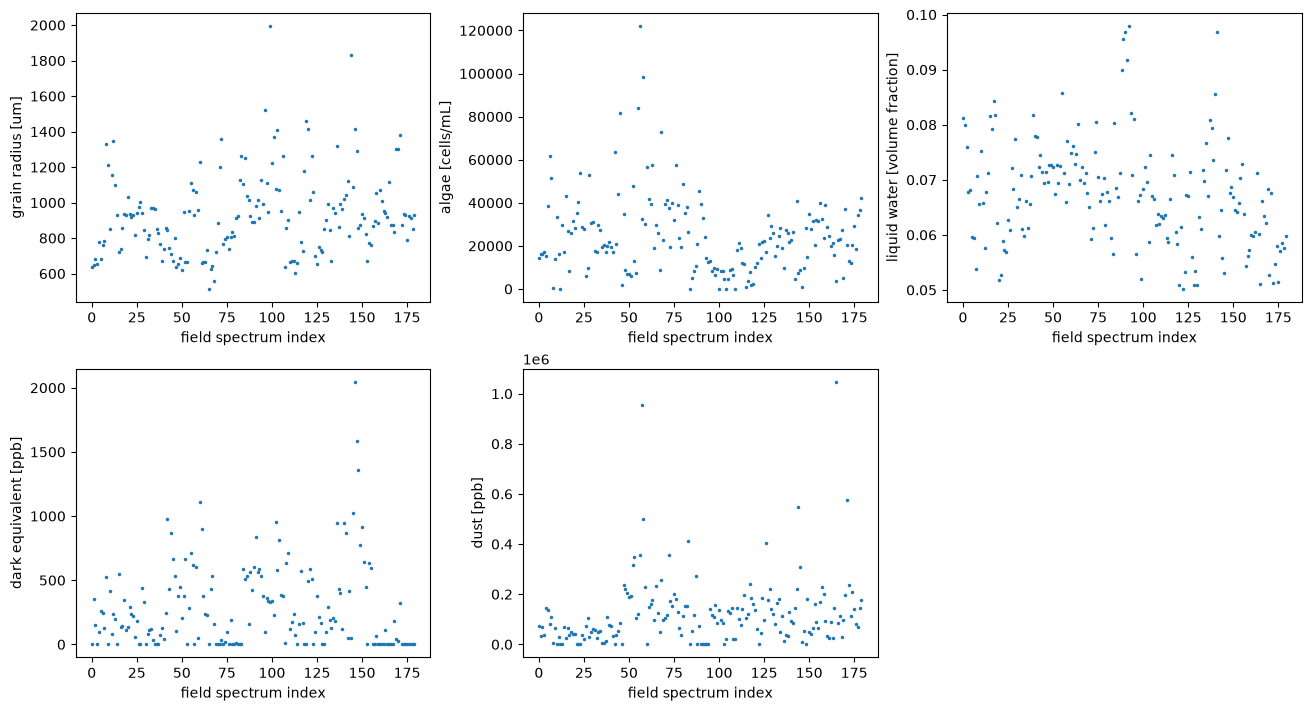

Four inferred-signature examples(clean/algae/dust/dark equivalent),not independent chemical labels: [12, 56, 165, 146]


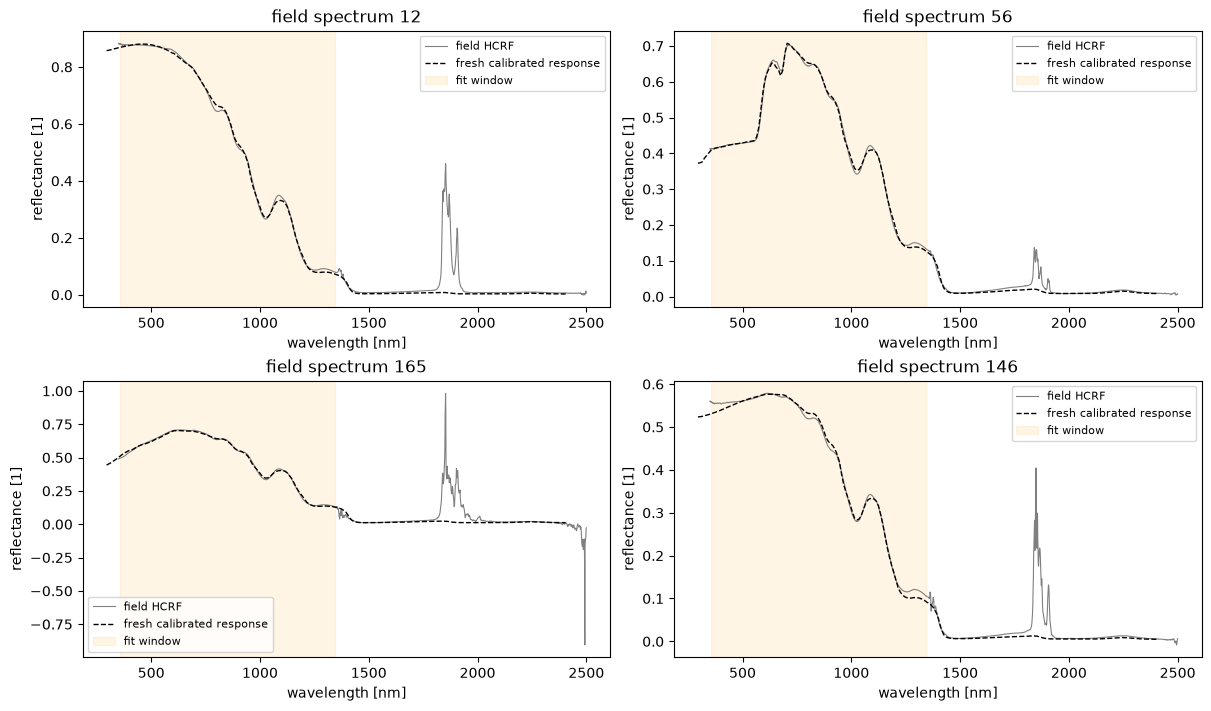

In [3]:
t=time.perf_counter();fresh,details=reconstruct(d);elapsed=time.perf_counter()-t
np.savez('output/reconstruction.npz',**fresh);q=fresh['reconstruction'][0];z=fresh['modeled_spectra'][0]
print('Complete active seconds',elapsed,'starts',details['starts'],'updates',details['iterations'])
property_panels(q);plt.show()
indices=[int(np.argmin(q[:,1]+q[:,3]+q[:,4]/100)),int(np.argmax(q[:,1])),int(np.argmax(q[:,4])),int(np.argmax(q[:,3]))]
print('Four inferred-signature examples(clean/algae/dust/dark equivalent),not independent chemical labels:',indices)
selected_spectra(d,z,indices);plt.show()

# 4. Actual source comparison and identifiability
The comparison below is the actually executed original1000x20sourceinverse on these same observations. Paper historicalmeanMAE0.0056/max0.0089is context only. This run's sourcefinalmodel is freshly evaluated against nativefloat64data;source-returnedpre-finalMAE is not substituted. A good response fit does not establish physicallyuniqueproperties. SlightBCextrapolation beyond the independenttraininggrid is identified rather than silently clamped.

| Actual method | Mean final MAE (1) | Worst spectrum MAE (1) |
|---|---:|---:|
| reproduced source returned final parameters | 0.00565066171449 | 0.00938375045159 |
| fresh complete local | 0.00565053476192 | 0.00936248029408 |

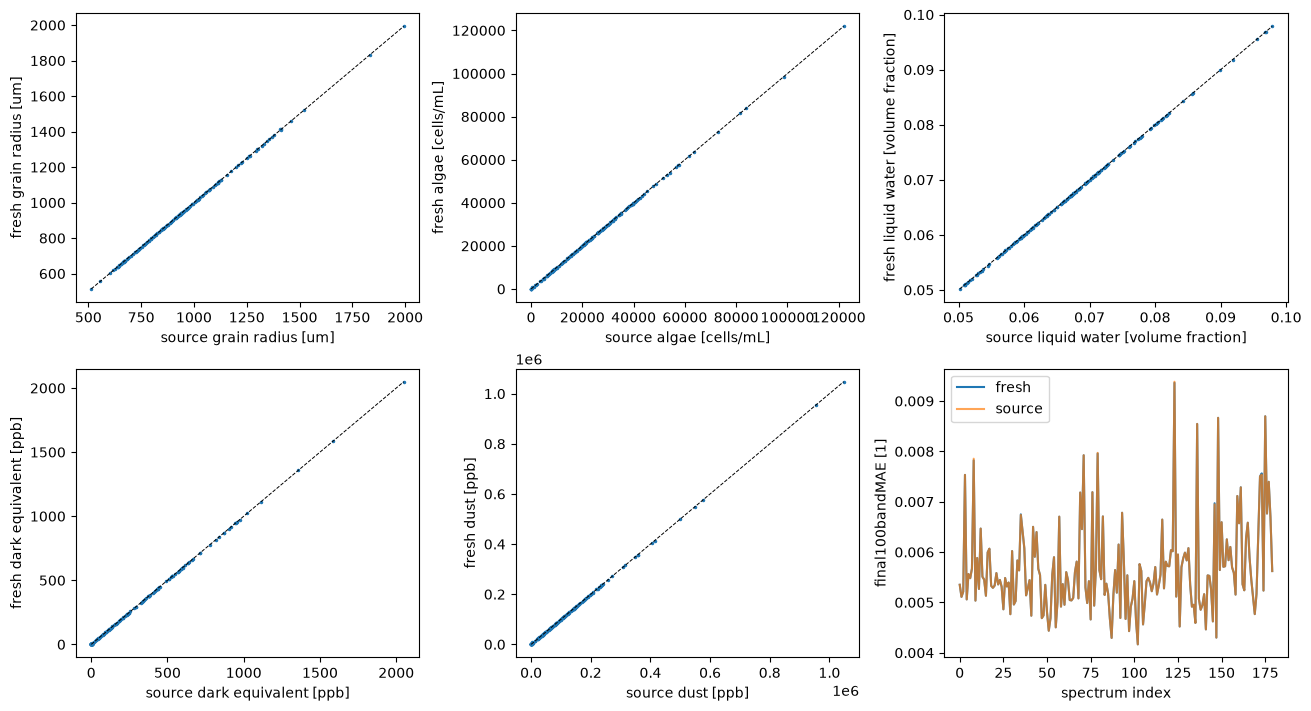

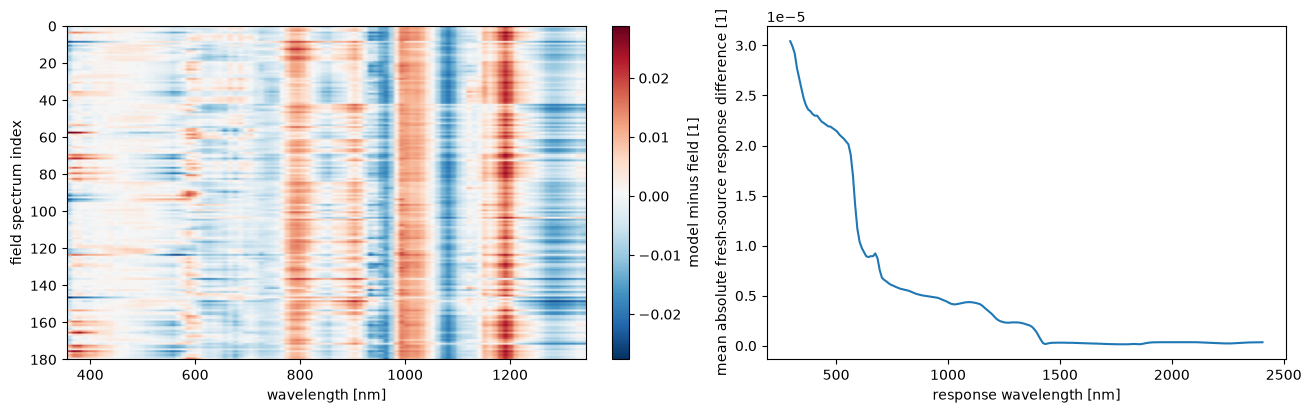

In [4]:
with np.load('notebooks/reference_outputs/upstream_fit.npz') as f:uq=f['reconstruction'][0];uz=f['modeled_spectra'][0]
def quality(model,data=d):
 e=np.mean(abs(model[:,6:106]-data['spectra'][:,5::10][:,:100]),1);return e.mean(),e.max()
rows=['| Actual method | Mean final MAE (1) | Worst spectrum MAE (1) |','|---|---:|---:|']
for name,model in [('reproduced source returned final parameters',uz),('fresh complete local',z)]:rows.append('| '+name+' | '+' | '.join(f'{v:.12g}' for v in quality(model))+' |')
display(Markdown('\n'.join(rows)))
fig,axs=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for j,ax in enumerate(axs.flat[:5]):
 ax.plot(uq[:,j],q[:,j],'.',ms=3);lo=min(uq[:,j].min(),q[:,j].min());hi=max(uq[:,j].max(),q[:,j].max());ax.plot([lo,hi],[lo,hi],'k--',lw=.7);ax.set_xlabel('source '+LABELS[j]);ax.set_ylabel('fresh '+LABELS[j])
axs.flat[5].plot(np.mean(abs(z[:,6:106]-target),1),label='fresh');axs.flat[5].plot(np.mean(abs(uz[:,6:106]-target),1),label='source',alpha=.7);axs.flat[5].set_xlabel('spectrum index');axs.flat[5].set_ylabel('final100bandMAE [1]');axs.flat[5].legend();plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained');im=axs[0].imshow(z[:,6:106]-target,aspect='auto',cmap='RdBu_r',extent=[355,1345,180,0]);fig.colorbar(im,ax=axs[0],label='model minus field [1]');axs[0].set_xlabel('wavelength [nm]');axs[0].set_ylabel('field spectrum index');axs[1].plot(wave,np.mean(abs(z-uz),axis=0));axs[1].set_xlabel('response wavelength [nm]');axs[1].set_ylabel('mean absolute fresh-source response difference [1]');plt.show()

# 5. Optical counterfactuals and actual robustness refits
Removing oneinferredLAPwhileholdinggrain/waterfixed is an actual forwardcounterfactual,not a refit or a measured attribution. Nonlinearinteraction means three marginalalbedochanges neednot sumto theallLAPchange. We retain this spectralcomparisonwithout claimingunavailablegroundirradianceor fullradiativeforcing.

The following limitedbudgetinverse diagnostics actuallyrefit perturbedrawspectra(0.002dimensionlessGaussianamplitude) and nominalangle+2degrees. Eachuses400updates4starts;they are sensitivitychecks,not replacementsfor thecomplete1000x20benchmark. The angleperturbation is not a clock correction or inventedcalibration.
A matched400x4nominalcontrol uses the same seed/initializations as both perturbation refits. Reported property-sensitivity ratios compare against that matchedcontrol, so finitebudget/initializationchanges are not attributed to observation changes.


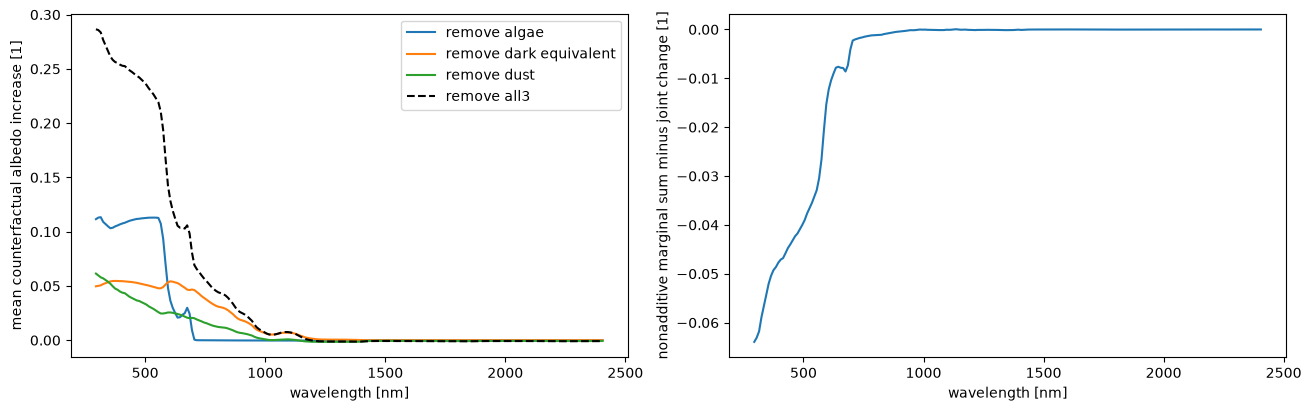

Actual matched control plus two diagnostic refits seconds 37.94032629998401


| Computed method/acquisition | MAE on bound original spectra (1) | Worst spectrum MAE (1) |
|---|---:|---:|
| standard nominal fullbudget | 0.00565053476192 | 0.00936248029408 |
| nominal matched diagnosticbudget | 0.00571390199238 | 0.00939913582601 |
| perturbed reflectance,matchedbudget | 0.00572380611446 | 0.00935970899262 |
| angle+2degree,matchedbudget | 0.0056858825865 | 0.00946387161114 |

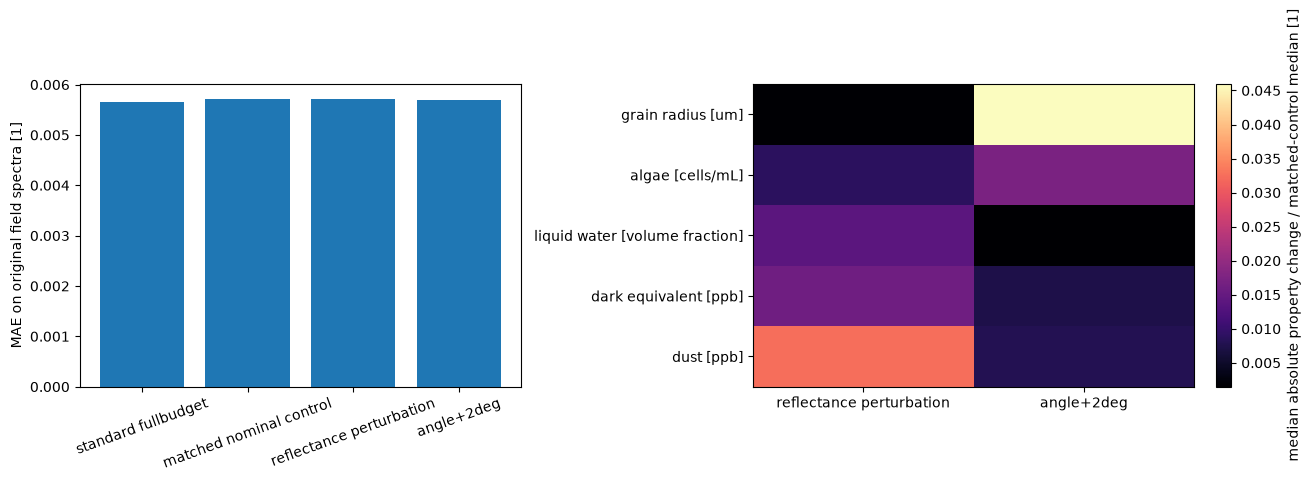

In [5]:
effects=[]
for j in [1,3,4]:
 alternative=q.copy();alternative[:,j]=0;effects.append(spectrum(alternative,d)-z)
cleanq=q.copy();cleanq[:,[1,3,4]]=0;allchange=spectrum(cleanq,d)-z
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for a,name in zip(effects,['remove algae','remove dark equivalent','remove dust']):axs[0].plot(wave,a.mean(0),label=name)
axs[0].plot(wave,allchange.mean(0),'k--',label='remove all3');axs[0].set_xlabel('wavelength [nm]');axs[0].set_ylabel('mean counterfactual albedo increase [1]');axs[0].legend();axs[1].plot(wave,(sum(effects)-allchange).mean(0));axs[1].set_xlabel('wavelength [nm]');axs[1].set_ylabel('nonadditive marginal sum minus joint change [1]');plt.show()
noise={k:v.copy() for k,v in d.items()};noise['spectra']+=np.random.default_rng(99).normal(0,.002,noise['spectra'].shape)
angle={k:v.copy() for k,v in d.items()};angle['solar_zenith']+=2
t=time.perf_counter();control,_=reconstruct(d,steps=400,repeats=4,seed=21);nr,_=reconstruct(noise,steps=400,repeats=4,seed=21);ar,_=reconstruct(angle,steps=400,repeats=4,seed=21);print('Actual matched control plus two diagnostic refits seconds',time.perf_counter()-t)
rows=['| Computed method/acquisition | MAE on bound original spectra (1) | Worst spectrum MAE (1) |','|---|---:|---:|']
for name,result in [('standard nominal fullbudget',fresh),('nominal matched diagnosticbudget',control),('perturbed reflectance,matchedbudget',nr),('angle+2degree,matchedbudget',ar)]:rows.append('| '+name+' | '+' | '.join(f'{v:.12g}' for v in quality(result['modeled_spectra'][0]))+' |')
display(Markdown('\n'.join(rows)))
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained');axs[0].bar(range(4),[quality(result['modeled_spectra'][0])[0] for result in [fresh,control,nr,ar]]);axs[0].set_xticks(range(4),['standard fullbudget','matched nominal control','reflectance perturbation','angle+2deg'],rotation=20);axs[0].set_ylabel('MAE on original field spectra [1]')
cq=control['reconstruction'][0];scale=np.maximum(np.median(abs(cq),axis=0),1e-12);changes=np.c_[np.median(abs(nr['reconstruction'][0]-cq)/scale,axis=0),np.median(abs(ar['reconstruction'][0]-cq)/scale,axis=0)];im=axs[1].imshow(changes,aspect='auto',cmap='magma');axs[1].set_yticks(range(5),LABELS);axs[1].set_xticks([0,1],['reflectance perturbation','angle+2deg']);fig.colorbar(im,ax=axs[1],label='median absolute property change / matched-control median [1]');plt.show()

# 6. Evaluation and scientific conclusion
The standaloneJudge validates allfivephysicalquantities and all212bands. It requires positivephysicalbounds,exactdeclaredshapes/dtypes,finitevalues,fullforwardconsistency,and jointmean/worst100bandfitquality. It accepts equivalent or betterconditionalresponsefitswithoutenforcingonerandomtrajectory. No latentfield-propertytruthis claimed.

The mainlimits are calibrationapproximation,anisotropicHCRFversusalbedo,nominalSZAerror,homogeneouslayerassumptions and compositiontradeoffs. IndependentRTMtrainingemulatorerrorreportedinthepaperis historicalcalibrationvalidation,not a newlyexecutedRTEcomparison. InferredBC-likeabundancecannotbe interpretedas measuredBCchemistry. These180discretefieldmeasurements do not establish an unmeasuredspatialmap.

In [6]:
import subprocess
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8')
print(Path('output/judge_report.json').read_text(encoding='utf8'));assert p.returncode==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "mean_absolute_spectral_error": 0.005650534761918309,
    "worst_spectrum_absolute_error": 0.009362480294078159,
    "forward_consistency_max": 0.0
  },
  "thresholds": {
    "mean_absolute_spectral_error": {
      "comparison": "<=",
      "boundary": 0.0056507617144896235
    },
    "worst_spectrum_absolute_error": {
      "comparison": "<=",
      "boundary": 0.00938475045158639
    },
    "forward_consistency_max": {
      "comparison": "<=",
      "boundary": 2e-06
    }
  },
  "errors": []
}


The actual LAP-removal diagnostics show small negative spectral changes in some bands. The calibrated emulator does not enforce spectral monotonicity with each LAP input; these local negative changes are a limitation of the approximate emulator response. They are not evidence for particle chemistry, a measured beneficial impurity effect, or independently validated radiative forcing.